# Collaboration step 1, notebook 1: the public data, cleaning, the guard layer and the baselines

Protocol: [SUBSTANCE_PROTOCOL.md](../SUBSTANCE_PROTOCOL.md). The student dataset is far too small to train a comment scorer on (the real students wrote 12 reviews and 1 comment, none
over 10 words), so the scorer is trained on public labeled review comments and the student texts are only scored.

**What the labels mean.** Both public sets label a comment *useful* when the code author acted on it (OpenStack Nova, Gerrit). That is related to, not the same as, "substantive", and it depends on the code the
comment was about, which a text-only scorer does not see. Results are therefore about *usefulness in a professional project*, not about collaboration among students.

In [1]:
import sys, warnings, json
from pathlib import Path
warnings.filterwarnings("ignore")
sys.path.insert(0, str(Path(".").resolve()))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import spearmanr
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 170); pd.set_option("display.max_colwidth", 80); pd.set_option("display.max_columns", 30)
import data, substance
from cleaning import substance as rule_score, clean_text, is_padding, APPROVAL_ONLY
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)
od, rh = data.public_pool()
od = od.reset_index(drop=True); rh = rh.reset_index(drop=True)
CS = substance.combos(od.group.to_numpy())
OUTER = {}
for o, i, tr, va, te in CS:
    OUTER[o] = (np.setdiff1d(np.arange(len(od)), te), te)
def guarded(original):
    c = clean_text(original)
    return len(c.split()) < 3 or bool(APPROVAL_ONLY.match(c)) or is_padding(c)

## 1. The data

,comments,useful,not useful,useful share,median words,empty after cleaning,groups (changes),guarded (would score 0)
set,,,,,,,,
OpenDev,2500,2052,448,0.821,13.0,9,375,488
RevHelper,1464,877,587,0.599,15.0,19,510,94


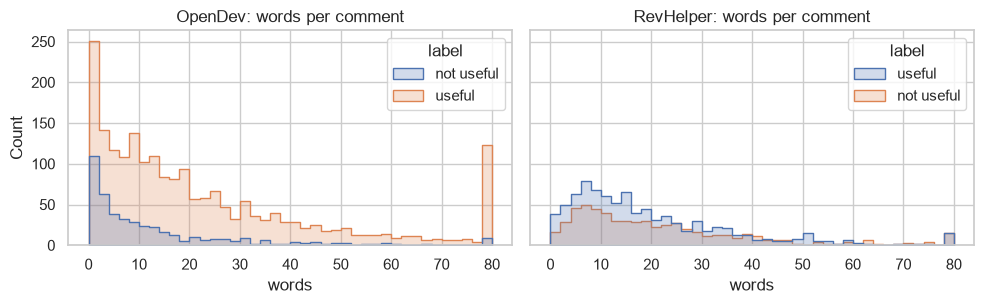

In [2]:
rows = []
for name, d in (("OpenDev", od), ("RevHelper", rh)):
    w = d.clean.str.split().str.len()
    rows.append({"set": name, "comments": len(d), "useful": int(d.y.sum()), "not useful": int((1 - d.y).sum()), "useful share": d.y.mean(), "median words": w.median(),
                 "empty after cleaning": int((w == 0).sum()), "groups (changes)": d.group.nunique(), "guarded (would score 0)": int(sum(guarded(t) for t in d.text))})
display(pd.DataFrame(rows).set_index("set").round(3))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for a, (n, d) in zip(ax, (("OpenDev", od), ("RevHelper", rh))):
    sns.histplot(data=d.assign(words=d.clean.str.split().str.len().clip(upper=80), label=d.y.map({1: "useful", 0: "not useful"})), x="words", hue="label", bins=40, ax=a, element="step")
    a.set_title(n + ": words per comment")
fig.tight_layout(); plt.show()

## 2. The guard layer

Approval-only text ("LGTM", "ok"), text under 3 words after cleaning, and padding score 0 in the pipeline and never reach the model. This protects against comment spam, but in the public sets some very short
comments ("Ditto.") *are* labeled useful, so the guard costs some agreement with the public labels. The table shows how many and what.

In [3]:
for name, d in (("OpenDev", od), ("RevHelper", rh)):
    g = np.array([guarded(t) for t in d.text])
    print(f"{name}: guarded {g.sum()} comments ({g.mean():.1%}); of them labeled useful: {d.y[g].mean():.1%} (all comments: {d.y.mean():.1%})")
display(od[[guarded(t) for t in od.text]].sample(8, random_state=1)[["text", "y"]])

OpenDev: guarded 488 comments (19.5%); of them labeled useful: 69.9% (all comments: 82.1%)
RevHelper: guarded 94 comments (6.4%); of them labeled useful: 64.9% (all comments: 59.9%)


,text,y
1900,Here,1
720,ditto,1
1117,nit:,1
2255,API operation?,1
2159,nit: period,0
1116,Not needed.,1
1303,noyce,1
1131,whitespace damage,0


## 3. Baselines on the protocol's folds

Five outer folds grouped by code change (the same folds notebook 2 uses). Baselines: a constant, comment length alone, the rule-based score of `cleaning.py`, and TF-IDF with logistic regression.
The two external directions are train OpenDev / test RevHelper and the reverse.

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

def tfidf():
    return make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True), LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000))

def predict(kind, Xtr, ytr, Xte):
    if kind == "constant":
        return np.full(len(Xte), float(np.mean(ytr)))
    if kind == "length only":
        f = lambda X: np.log1p([len(t.split()) for t in X])[:, None]
        return LogisticRegression(class_weight="balanced").fit(f(Xtr), ytr).predict_proba(f(Xte))[:, 1]
    if kind == "rules (cleaning.py)":
        return np.array([rule_score(t) for t in Xte])
    return tfidf().fit(list(Xtr), ytr).predict_proba(list(Xte))[:, 1]

KINDS = ["constant", "length only", "rules (cleaning.py)", "TF-IDF + logistic"]
def view(kind, d, idx=None):
    col = d.text if kind == "rules (cleaning.py)" else d.clean   # the rule score reads the original text, the others the cleaned text
    return (col if idx is None else col.iloc[idx]).to_numpy()
oof = {k: np.zeros(len(od)) for k in KINDS}
for o, (tr, te) in OUTER.items():
    for k in KINDS:
        oof[k][te] = predict(k, view(k, od, tr), od.y.iloc[tr].to_numpy(), view(k, od, te))
rows = {}
for k in KINDS:
    s = substance.auc_scores(od.y, oof[k]); lo, hi = substance.group_bootstrap_auc(od.y, oof[k], od.group)
    ext1 = predict(k, view(k, od), od.y.to_numpy(), view(k, rh))
    ext2 = predict(k, view(k, rh), rh.y.to_numpy(), view(k, od))
    rows[k] = {"OpenDev grouped CV AUC": s["AUC"], "95% low": lo, "95% high": hi, "OpenDev -> RevHelper AUC": substance.auc_scores(rh.y, ext1)["AUC"],
               "RevHelper -> OpenDev AUC": substance.auc_scores(od.y, ext2)["AUC"], "Brier (CV)": s["Brier"]}
base = pd.DataFrame(rows).T
base.round(3)

,OpenDev grouped CV AUC,95% low,95% high,OpenDev -> RevHelper AUC,RevHelper -> OpenDev AUC,Brier (CV)
constant,0.467,0.433,0.504,0.500,0.500,0.147
length only,0.650,0.619,0.683,0.470,0.347,0.233
rules (cleaning.py),0.649,0.615,0.681,0.473,0.649,0.330
TF-IDF + logistic,0.713,0.680,0.746,0.530,0.491,0.183


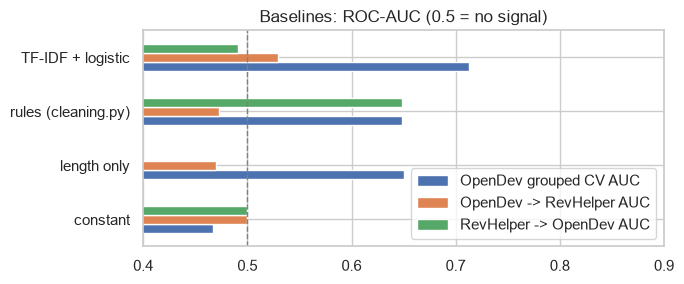

In [5]:
base.to_csv(RESULTS / "baselines.csv")
pd.DataFrame({k: oof[k] for k in KINDS}).assign(y=od.y.to_numpy(), group=od.group.to_numpy()).to_csv(RESULTS / "baseline_oof.csv", index=False)
fig, ax = plt.subplots(figsize=(7, 3)); base[["OpenDev grouped CV AUC", "OpenDev -> RevHelper AUC", "RevHelper -> OpenDev AUC"]].plot.barh(ax=ax)
ax.axvline(0.5, color="grey", ls="--", lw=1); ax.set_xlim(0.4, 0.9); ax.set_title("Baselines: ROC-AUC (0.5 = no signal)"); fig.tight_layout(); plt.show()

## 4. Reading the results

**What the baselines show.**
- Within OpenDev (grouped by code change) the best baseline is TF-IDF with logistic regression at AUC 0.71 (95% interval 0.68 to 0.75). Comment length alone and the rule score in `cleaning.py` reach about 0.65. The constant model is at 0.47, which is what no signal looks like once the folds' differing useful shares are accounted for.
- **Across the two public sets every baseline collapses to about 0.5 or worse.** Length alone scores 0.47 when trained on OpenDev and tested on RevHelper and **0.35** the other way round, so the length-to-usefulness relation has the opposite sign in the two sets. The sets label "useful" differently: OpenDev is 82% useful and includes very short comments ("ditto", "nit:", "Not needed.") that the author acted on; RevHelper is 60% useful and its useful comments are longer.
- The labels mean "the author acted on this comment", which depends on the code the comment was about. A text-only scorer cannot see that code, so the ceiling for any text-only model is low, and it is set mostly by how each dataset was labeled.

**The guard layer costs agreement with the public labels.** It scores approvals, texts under 3 words and padding as 0. That affects 19.5% of OpenDev comments, of which 70% are labeled useful (6.4% of RevHelper, 65% useful). For student comments this is the right design, because it blocks comment spam, but it means the public labels can never reward a short "ditto".

**What this does not show.** Nothing here measures how well any scorer works on student comments.